In [1]:
from pathlib import Path
from collections import Counter
from io import BytesIO
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
DATA_DIR = Path(
    r"C:\Users\rajab\202618066_Abhikarsh_Raj_DS605\202618066_LAB_7\Data"
)

print("Folder exists:", DATA_DIR.exists())

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Folder not found: {DATA_DIR}")

print("\nContents:")
for item in sorted(DATA_DIR.iterdir())[:50]:
    print(item.name)

Folder exists: True

Contents:
README
s1
s10
s11
s12
s13
s14
s15
s16
s17
s18
s19
s2
s20
s21
s22
s23
s24
s25
s26
s27
s28
s29
s3
s30
s31
s32
s33
s34
s35
s36
s37
s38
s39
s4
s40
s5
s6
s7
s8
s9


In [5]:
images = []
labels = []
records = []
errors = []

# Find images inside Data and its subfolders.
image_files = list(DATA_DIR.rglob("*.pgm"))

if not image_files:
    raise FileNotFoundError(
        f"No .pgm images found inside {DATA_DIR}"
    )

# Sort numerically: s1, s2, ..., s40; then image number.
image_files.sort(
    key=lambda path: (
        int(path.parent.name.removeprefix("s")),
        int(path.stem)
    )
)

for image_path in image_files:
    # The parent folder is the subject label, e.g. s1.
    subject = image_path.parent.name

    try:
        with Image.open(image_path) as image:
            image.load()
            mode = image.mode
            pixels = np.array(image)

        if pixels.ndim != 2:
            raise ValueError(
                f"Expected a grayscale image, got shape {pixels.shape}"
            )

        images.append(pixels)
        labels.append(subject)

        records.append({
            "filename": str(image_path.relative_to(DATA_DIR)),
            "subject": subject,
            "height": pixels.shape[0],
            "width": pixels.shape[1],
            "mode": mode,
            "dtype": str(pixels.dtype),
            "min_pixel": int(pixels.min()),
            "max_pixel": int(pixels.max()),
            "mean_brightness": float(pixels.mean())
        })

    except Exception as error:
        errors.append({
            "filename": str(image_path),
            "error": str(error)
        })

metadata = pd.DataFrame(records)

print("Images found:", len(image_files))
print("Images loaded:", len(images))
print("Unique subjects:", len(set(labels)))
print("Unreadable images:", len(errors))

display(metadata.head())

if errors:
    display(pd.DataFrame(errors))

Images found: 400
Images loaded: 400
Unique subjects: 40
Unreadable images: 0


,filename,subject,height,width,mode,dtype,min_pixel,max_pixel,mean_brightness
0,s1\1.pgm,s1,112,92,L,uint8,11,234,128.338218
1,s1\2.pgm,s1,112,92,L,uint8,2,223,147.988936
2,s1\3.pgm,s1,112,92,L,uint8,7,232,132.595497
3,s1\4.pgm,s1,112,92,L,uint8,5,215,142.149262
4,s1\5.pgm,s1,112,92,L,uint8,7,222,142.773486


Minimum images per subject: 10
Maximum images per subject: 10


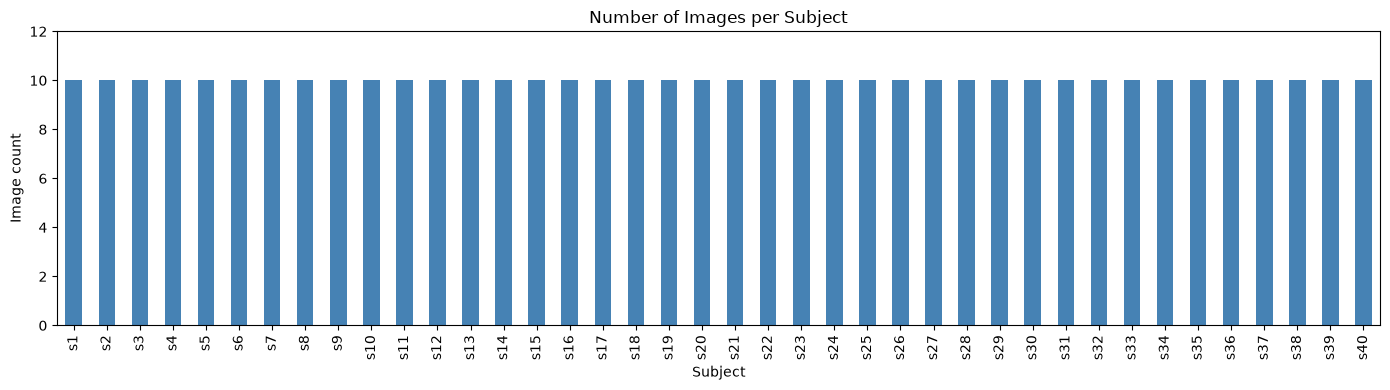

In [6]:
subject_counts = (
    metadata.groupby("subject")
    .size()
    .reindex([f"s{i}" for i in range(1, 41)])
)

print("Minimum images per subject:", subject_counts.min())
print("Maximum images per subject:", subject_counts.max())

plt.figure(figsize=(14, 4))
subject_counts.plot(kind="bar", color="steelblue")

plt.title("Number of Images per Subject")
plt.xlabel("Subject")
plt.ylabel("Image count")
plt.xticks(rotation=90)
plt.ylim(0, subject_counts.max() + 2)
plt.tight_layout()
plt.show()

In [9]:
images = np.stack(images)
y = np.array(labels)

print("Images shape:", images.shape)
print("Labels shape:", y.shape)
print("First five labels:", y[:5])

Images shape: (400, 112, 92)
Labels shape: (400,)
First five labels: ['s1' 's1' 's1' 's1' 's1']


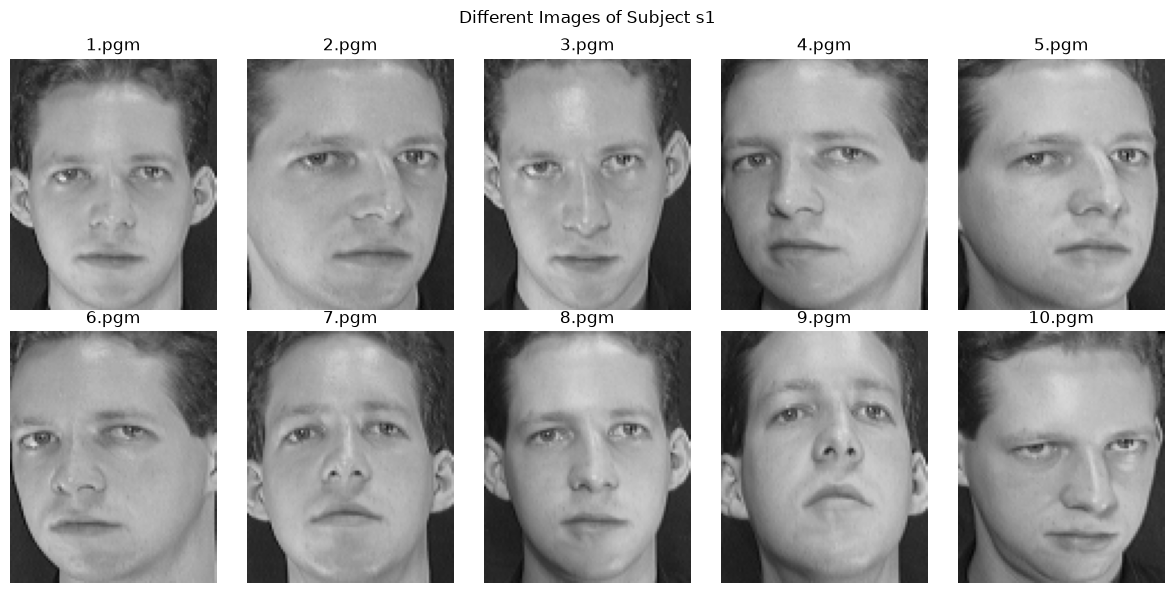

In [10]:
subject_to_view = "s1"
indices = np.where(y == subject_to_view)[0]

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for ax, index in zip(axes.flat, indices):
    ax.imshow(images[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(Path(metadata.iloc[index]["filename"]).name)
    ax.axis("off")

fig.suptitle(f"Different Images of Subject {subject_to_view}")
plt.tight_layout()
plt.show()

In [11]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)
constant_images = []

for index, image in enumerate(images):
    filename = metadata.iloc[index]["filename"]

    fingerprint = hashlib.sha256(
        str(image.shape).encode() + image.tobytes()
    ).hexdigest()

    hash_groups[fingerprint].append(filename)

    if image.min() == image.max():
        constant_images.append(filename)

duplicate_groups = [
    filenames
    for filenames in hash_groups.values()
    if len(filenames) > 1
]

print("Exact duplicate groups:", len(duplicate_groups))
print("Constant-intensity images:", len(constant_images))

if duplicate_groups:
    print("Duplicates:", duplicate_groups)

if constant_images:
    print("Constant images:", constant_images)

Exact duplicate groups: 0
Constant-intensity images: 0


## We examine average image brightness to understand intensity variation that may affect face recognition.

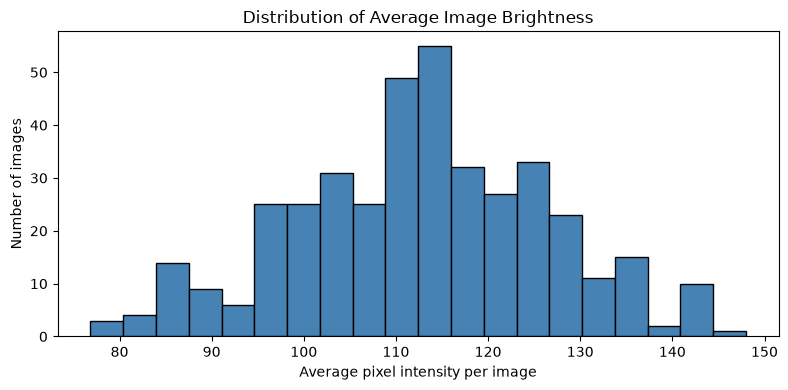

count    400.000000
mean     112.631285
std       13.796719
min       76.835598
25%      103.695725
50%      113.066285
75%      122.462199
max      147.988936
Name: mean_brightness, dtype: float64

In [12]:
plt.figure(figsize=(8, 4))

plt.hist(
    metadata["mean_brightness"],
    bins=20,
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of Average Image Brightness")
plt.xlabel("Average pixel intensity per image")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

display(metadata["mean_brightness"].describe())

## We flatten each image into 10,304 pixel features and convert them to floating-point numbers for PCA calculations.

In [13]:
X = images.reshape(len(images), -1).astype(np.float64)

print("Original image array shape:", images.shape)
print("Flattened feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Feature datatype:", X.dtype)

assert len(X) == len(y), "Image and label counts do not match."
assert np.isfinite(X).all(), "Features contain missing or infinite values."

Original image array shape: (400, 112, 92)
Flattened feature matrix shape: (400, 10304)
Labels shape: (400,)
Feature datatype: float64


## We create a reproducible train–test split with every subject in both sets to evaluate recognition on unseen images of known subjects.

In [14]:
rng = np.random.default_rng(42)

train_indices = []
test_indices = []

subjects = sorted(np.unique(y), key=lambda label: int(label[1:]))

for subject in subjects:
    subject_indices = np.where(y == subject)[0]
    shuffled_indices = rng.permutation(subject_indices)

    train_indices.extend(shuffled_indices[:7])
    test_indices.extend(shuffled_indices[7:])

train_indices = rng.permutation(np.array(train_indices))
test_indices = rng.permutation(np.array(test_indices))

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

# Verify that the split is complete and has no overlapping images.
assert set(train_indices).isdisjoint(test_indices)
assert len(train_indices) + len(test_indices) == len(X)
assert set(y_train) == set(y_test) == set(y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training images per subject:", np.unique(
    np.unique(y_train, return_counts=True)[1]
))
print("Testing images per subject:", np.unique(
    np.unique(y_test, return_counts=True)[1]
))

Training features: (280, 10304)
Testing features: (120, 10304)
Training images per subject: [7]
Testing images per subject: [3]


## We calculate the mean face from training images and subtract it from both sets so PCA uses centered data without learning from the test set.

Mean face shape: (10304,)
Centered training shape: (280, 10304)
Centered testing shape: (120, 10304)
Largest absolute training feature mean: 3.5425630682896424e-14


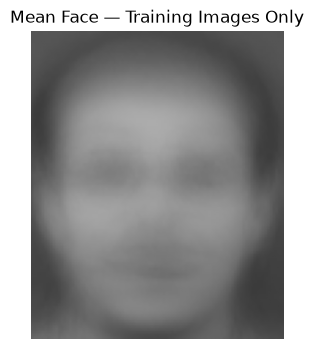

In [15]:
# Average each pixel position across training images.
mean_face = X_train.mean(axis=0)

# Use the same training mean to center both sets.
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Mean face shape:", mean_face.shape)
print("Centered training shape:", X_train_centered.shape)
print("Centered testing shape:", X_test_centered.shape)

# Each training feature should now have a mean close to zero.
print(
    "Largest absolute training feature mean:",
    np.abs(X_train_centered.mean(axis=0)).max()
)

assert np.allclose(X_train_centered.mean(axis=0), 0, atol=1e-10)

plt.figure(figsize=(4, 4))
plt.imshow(
    mean_face.reshape(images.shape[1:]),
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("Mean Face — Training Images Only")
plt.axis("off")
plt.show()

## We apply NumPy SVD to the centered training data to obtain principal directions and the variance explained by each component.

In [16]:
# Reduced SVD avoids creating an unnecessary 10304 × 10304 matrix.
U, singular_values, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Each row of Vt is a principal direction in pixel space.
principal_components = Vt

# Covariance eigenvalues obtained from singular values.
explained_variance = (
    singular_values ** 2 / (X_train_centered.shape[0] - 1)
)

explained_variance_ratio = (
    explained_variance / explained_variance.sum()
)

cumulative_variance = np.cumsum(explained_variance_ratio)

print("U shape:", U.shape)
print("Singular values shape:", singular_values.shape)
print("Principal components shape:", principal_components.shape)

print(
    "Variance explained by the first 5 components (%):",
    np.round(explained_variance_ratio[:5] * 100, 2)
)

print(
    "Total explained variance ratio:",
    explained_variance_ratio.sum()
)

U shape: (280, 280)
Singular values shape: (280,)
Principal components shape: (280, 10304)
Variance explained by the first 5 components (%): [17.76 12.58  7.07  5.72  5.08]
Total explained variance ratio: 1.0


## We select the smallest number of principal components that preserve at least 90% of training variance and plot the cumulative explained variance.

Components needed for 90% variance: 92
Variance retained: 90.04%
Variance with one fewer component: 89.92%


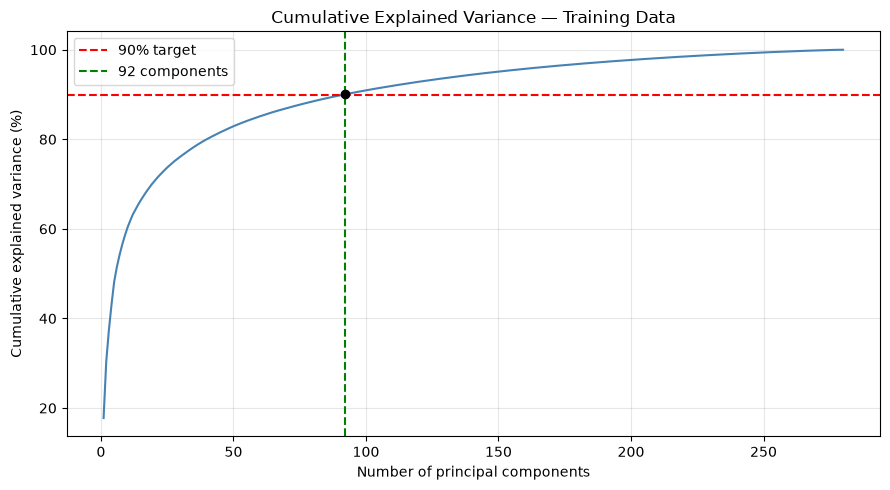

In [17]:
target_variance = 0.90

# Add 1 because array indices start at zero.
k_90 = int(
    np.searchsorted(cumulative_variance, target_variance) + 1
)

print("Components needed for 90% variance:", k_90)
print(
    "Variance retained:",
    f"{cumulative_variance[k_90 - 1] * 100:.2f}%"
)

if k_90 > 1:
    print(
        "Variance with one fewer component:",
        f"{cumulative_variance[k_90 - 2] * 100:.2f}%"
    )

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    color="steelblue"
)

plt.axhline(
    target_variance * 100,
    color="red",
    linestyle="--",
    label="90% target"
)

plt.axvline(
    k_90,
    color="green",
    linestyle="--",
    label=f"{k_90} components"
)

plt.scatter(
    k_90,
    cumulative_variance[k_90 - 1] * 100,
    color="black",
    zorder=3
)

plt.title("Cumulative Explained Variance — Training Data")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## We reshape the first 10 principal directions into eigenface images to visualize the main patterns of pixel variation learned from training faces.

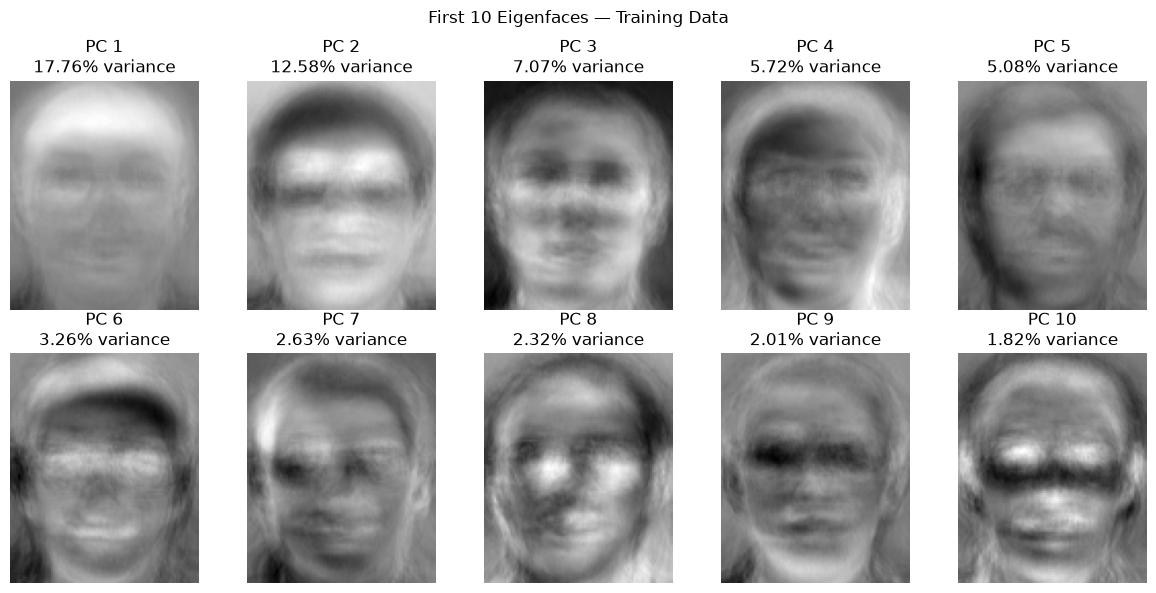

In [18]:
n_eigenfaces = 10
image_shape = images.shape[1:]

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    eigenface = principal_components[i].reshape(image_shape)

    # Symmetric limits display negative and positive weights.
    limit = np.abs(eigenface).max()

    ax.imshow(
        eigenface,
        cmap="gray",
        vmin=-limit,
        vmax=limit
    )
    ax.set_title(
        f"PC {i + 1}\n"
        f"{explained_variance_ratio[i] * 100:.2f}% variance"
    )
    ax.axis("off")

fig.suptitle("First 10 Eigenfaces — Training Data")
plt.tight_layout()
plt.show()

## We project training and test images onto the 92 training-derived principal components to represent each face with fewer features while retaining 90.04% of training variance.

In [19]:
# Select the first 92 principal directions.
W = principal_components[:k_90].T

# Project centered images into PCA space.
Z_train = X_train_centered @ W
Z_test = X_test_centered @ W

print("Projection matrix shape:", W.shape)
print("Reduced training shape:", Z_train.shape)
print("Reduced testing shape:", Z_test.shape)

print(
    "Feature-count reduction:",
    f"{(1 - k_90 / X_train.shape[1]) * 100:.2f}%"
)

Projection matrix shape: (10304, 92)
Reduced training shape: (280, 92)
Reduced testing shape: (120, 92)
Feature-count reduction: 99.11%


## We reconstruct faces from their 92 PCA coordinates to visualize the detail retained and measure the information lost during dimensionality reduction.

Training reconstruction MSE: 154.43
Testing reconstruction MSE: 335.52


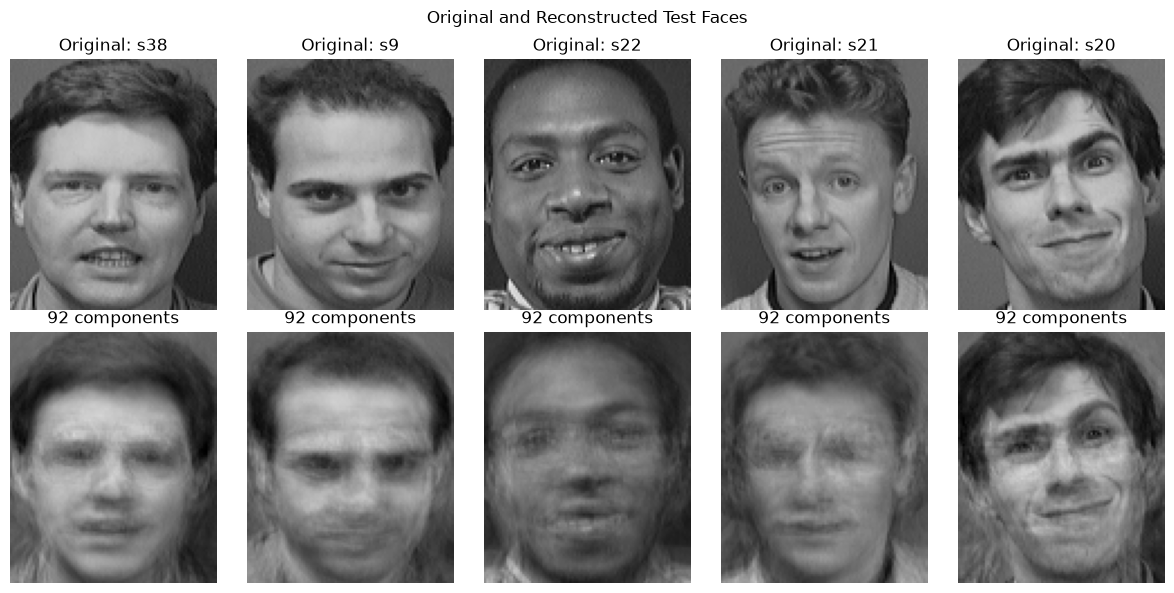

In [20]:
# Reconstruct pixel values from PCA coordinates.
X_train_reconstructed = Z_train @ W.T + mean_face
X_test_reconstructed = Z_test @ W.T + mean_face

# Calculate error using the original, unclipped reconstructions.
train_mse = np.mean((X_train - X_train_reconstructed) ** 2)
test_mse = np.mean((X_test - X_test_reconstructed) ** 2)

print(f"Training reconstruction MSE: {train_mse:.2f}")
print(f"Testing reconstruction MSE: {test_mse:.2f}")

# Compare the first five test images with their reconstructions.
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i in range(5):
    axes[0, i].imshow(
        X_test[i].reshape(image_shape),
        cmap="gray", vmin=0, vmax=255
    )
    axes[0, i].set_title(f"Original: {y_test[i]}")
    axes[0, i].axis("off")

    # Clip only for display.
    reconstructed = np.clip(X_test_reconstructed[i], 0, 255)

    axes[1, i].imshow(
        reconstructed.reshape(image_shape),
        cmap="gray", vmin=0, vmax=255
    )
    axes[1, i].set_title(f"{k_90} components")
    axes[1, i].axis("off")

plt.suptitle("Original and Reconstructed Test Faces")
plt.tight_layout()
plt.show()

## We compute PCA through a smaller Gram-matrix eigendecomposition and compare it with SVD to verify that both methods recover the same retained principal subspace.

In [21]:
n_train = X_train_centered.shape[0]

# A smaller 280 × 280 matrix instead of 10304 × 10304.
gram_matrix = (
    X_train_centered @ X_train_centered.T
) / (n_train - 1)

eigenvalues, eigenvectors = np.linalg.eigh(gram_matrix)

# Sort from largest to smallest eigenvalue.
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Map the leading Gram eigenvectors back into pixel space.
W_eig = (
    X_train_centered.T @ eigenvectors[:, :k_90]
) / np.sqrt((n_train - 1) * eigenvalues[:k_90])

# Compare retained eigenvalues.
relative_error = (
    np.linalg.norm(eigenvalues[:k_90] - explained_variance[:k_90])
    / np.linalg.norm(explained_variance[:k_90])
)

# Subspace comparison handles sign flips and rotated equivalent bases.
subspace_cosines = np.linalg.svd(
    W.T @ W_eig,
    compute_uv=False
)

print("Gram matrix shape:", gram_matrix.shape)
print("Eigenface basis shape:", W_eig.shape)
print(f"Relative eigenvalue error: {relative_error:.3e}")
print(
    "Smallest principal-angle cosine:",
    f"{subspace_cosines.min():.12f}"
)

assert np.allclose(
    eigenvalues[:k_90],
    explained_variance[:k_90],
    rtol=1e-8
)

assert np.allclose(subspace_cosines, 1.0, atol=1e-8)

Gram matrix shape: (280, 280)
Eigenface basis shape: (10304, 92)
Relative eigenvalue error: 1.231e-15
Smallest principal-angle cosine: 1.000000000000


## We compare raw-pixel storage with PCA coordinates plus the shared basis and mean face to measure the actual representation storage cost.

In [22]:
# Array payload sizes; excludes labels and file-format overhead.
raw_uint8_bytes = images.nbytes
raw_float64_bytes = X.nbytes

coordinate_bytes = Z_train.nbytes + Z_test.nbytes
basis_bytes = W.nbytes
mean_bytes = mean_face.nbytes

pca_total_bytes = coordinate_bytes + basis_bytes + mean_bytes

storage_table = pd.DataFrame({
    "Representation": [
        "Original pixels (uint8)",
        "Original pixels (float64)",
        "PCA coordinates only (float64)",
        "PCA basis + mean (float64)",
        "Complete PCA representation (float64)"
    ],
    "Size (MiB)": [
        raw_uint8_bytes / 1024**2,
        raw_float64_bytes / 1024**2,
        coordinate_bytes / 1024**2,
        (basis_bytes + mean_bytes) / 1024**2,
        pca_total_bytes / 1024**2
    ]
})

display(storage_table.round(3))

print(
    "Complete PCA size relative to original uint8 pixels:",
    f"{pca_total_bytes / raw_uint8_bytes:.2f}×"
)

print(
    "Storage reduction compared with float64 pixels:",
    f"{(1 - pca_total_bytes / raw_float64_bytes) * 100:.2f}%"
)

,Representation,Size (MiB)
0,Original pixels (uint8),3.931
1,Original pixels (float64),31.445
2,PCA coordinates only (float64),0.281
3,PCA basis + mean (float64),7.311
4,Complete PCA representation (float64),7.592


Complete PCA size relative to original uint8 pixels: 1.93×
Storage reduction compared with float64 pixels: 75.86%


## We compare nearest-face recognition using raw pixels and PCA features to measure how dimensionality reduction affects test accuracy.

In [23]:
def nearest_face_predict(train_features, test_features, train_labels):
    # Squared Euclidean distances between every test and training face.
    distances_squared = (
        np.sum(test_features ** 2, axis=1, keepdims=True)
        + np.sum(train_features ** 2, axis=1)[None, :]
        - 2 * test_features @ train_features.T
    )

    # Remove tiny negative values caused by floating-point rounding.
    distances_squared = np.maximum(distances_squared, 0)

    nearest_indices = np.argmin(distances_squared, axis=1)
    predictions = train_labels[nearest_indices]

    return predictions, nearest_indices


# Baseline 1: original pixel features.
pred_raw, nearest_raw = nearest_face_predict(
    X_train, X_test, y_train
)

# Baseline 2: 92 PCA features.
pred_pca, nearest_pca = nearest_face_predict(
    Z_train, Z_test, y_train
)

accuracy_raw = np.mean(pred_raw == y_test)
accuracy_pca = np.mean(pred_pca == y_test)

baseline_results = pd.DataFrame({
    "Method": [
        "Nearest face — raw pixels",
        "Nearest face — PCA"
    ],
    "Features": [X_train.shape[1], Z_train.shape[1]],
    "Correct predictions": [
        np.sum(pred_raw == y_test),
        np.sum(pred_pca == y_test)
    ],
    "Test images": [len(y_test), len(y_test)],
    "Accuracy (%)": [
        accuracy_raw * 100,
        accuracy_pca * 100
    ]
})

display(baseline_results.round(2))

,Method,Features,Correct predictions,Test images,Accuracy (%)
0,Nearest face — raw pixels,10304,117,120,97.5
1,Nearest face — PCA,92,117,120,97.5


## We display correct and incorrect PCA matches to inspect where nearest-face recognition succeeds and fails.

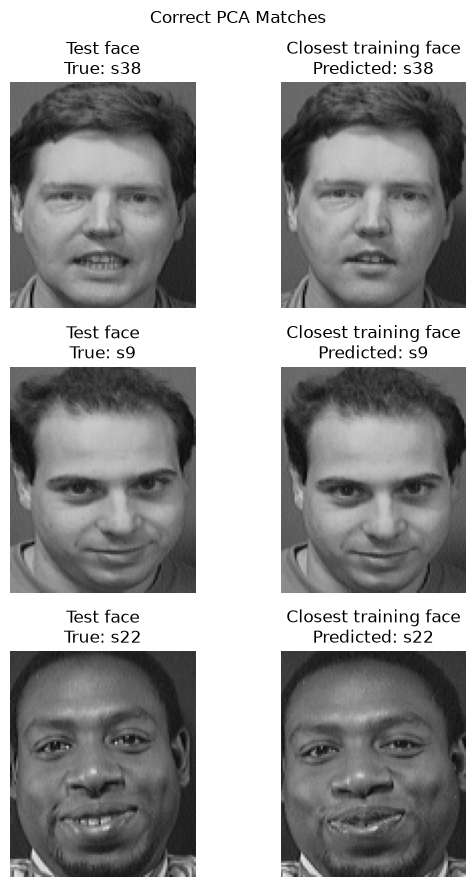

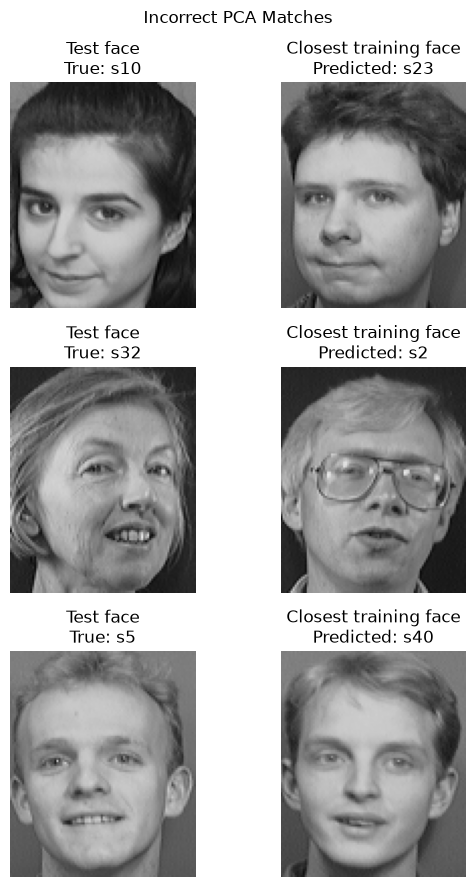

Incorrect PCA predictions: 3
Test images where raw-pixel and PCA predictions differ: 2


In [24]:
correct_indices = np.where(pred_pca == y_test)[0]
incorrect_indices = np.where(pred_pca != y_test)[0]

def show_matches(test_positions, title, max_examples=3):
    selected = test_positions[:max_examples]

    if len(selected) == 0:
        print(f"{title}: no examples.")
        return

    fig, axes = plt.subplots(
        len(selected), 2,
        figsize=(6, 3 * len(selected)),
        squeeze=False
    )

    for row, test_position in enumerate(selected):
        train_position = nearest_pca[test_position]

        axes[row, 0].imshow(
            X_test[test_position].reshape(image_shape),
            cmap="gray", vmin=0, vmax=255
        )
        axes[row, 0].set_title(
            f"Test face\nTrue: {y_test[test_position]}"
        )

        axes[row, 1].imshow(
            X_train[train_position].reshape(image_shape),
            cmap="gray", vmin=0, vmax=255
        )
        axes[row, 1].set_title(
            f"Closest training face\nPredicted: {pred_pca[test_position]}"
        )

        for ax in axes[row]:
            ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_matches(correct_indices, "Correct PCA Matches")
show_matches(incorrect_indices, "Incorrect PCA Matches")

print("Incorrect PCA predictions:", len(incorrect_indices))
print(
    "Test images where raw-pixel and PCA predictions differ:",
    np.sum(pred_raw != pred_pca)
)

## We split the training set into fitting and validation subsets and refit PCA only on fitting images to tune classifiers without leaking validation or test information.

In [25]:
rng_validation = np.random.default_rng(123)

fit_indices = []
validation_indices = []

for subject in subjects:
    positions = np.where(y_train == subject)[0]
    positions = rng_validation.permutation(positions)

    # Of the 7 training images per subject:
    # 5 for fitting, 2 for validation.
    fit_indices.extend(positions[:5])
    validation_indices.extend(positions[5:])

fit_indices = np.array(fit_indices)
validation_indices = np.array(validation_indices)

X_fit = X_train[fit_indices]
X_validation = X_train[validation_indices]

y_fit = y_train[fit_indices]
y_validation = y_train[validation_indices]

# Learn a separate PCA using only fitting images.
mean_fit = X_fit.mean(axis=0)

X_fit_centered = X_fit - mean_fit
X_validation_centered = X_validation - mean_fit

_, singular_values_fit, Vt_fit = np.linalg.svd(
    X_fit_centered,
    full_matrices=False
)

variance_ratio_fit = (
    singular_values_fit ** 2
    / np.sum(singular_values_fit ** 2)
)

k_90_fit = int(
    np.searchsorted(np.cumsum(variance_ratio_fit), 0.90) + 1
)

# Keep scores for all directions so we can compare component counts.
Z_fit_all = X_fit_centered @ Vt_fit.T
Z_validation_all = X_validation_centered @ Vt_fit.T

assert set(fit_indices).isdisjoint(validation_indices)
assert set(y_fit) == set(y_validation) == set(y_train)

print("Fitting images:", X_fit.shape)
print("Validation images:", X_validation.shape)
print("Fitting-only components for 90% variance:", k_90_fit)
print("Test images remain reserved:", X_test.shape[0])

Fitting images: (200, 10304)
Validation images: (80, 10304)
Fitting-only components for 90% variance: 75
Test images remain reserved: 120


## We compare PCA component counts, neighbour counts, and voting weights on validation data to select KNN settings without using test accuracy.

In [26]:

from sklearn.neighbors import KNeighborsClassifier

component_options = sorted(set([25, 50, k_90_fit, 100, 150]))
neighbor_options = [1, 3, 5, 7]
weight_options = ["uniform", "distance"]

knn_records = []

for n_components in component_options:
    for n_neighbors in neighbor_options:
        for weights in weight_options:
            model = KNeighborsClassifier(
                n_neighbors=n_neighbors,
                weights=weights,
                metric="euclidean"
            )

            model.fit(
                Z_fit_all[:, :n_components],
                y_fit
            )

            validation_predictions = model.predict(
                Z_validation_all[:, :n_components]
            )

            knn_records.append({
                "Components": n_components,
                "Neighbors": n_neighbors,
                "Weights": weights,
                "Validation accuracy (%)": (
                    np.mean(validation_predictions == y_validation) * 100
                )
            })

# Tie-break: fewer components, then fewer neighbors,
# then uniform voting.
knn_results = pd.DataFrame(knn_records).sort_values(
    by=[
        "Validation accuracy (%)",
        "Components",
        "Neighbors",
        "Weights"
    ],
    ascending=[False, True, True, False]
).reset_index(drop=True)

best_knn_settings = knn_results.iloc[0]

display(knn_results.head(10))

print("Selected KNN settings:")
print(best_knn_settings.to_string())

,Components,Neighbors,Weights,Validation accuracy (%)
0,25,1,uniform,92.50
1,25,1,distance,92.50
2,50,1,uniform,91.25
3,50,1,distance,91.25
4,75,1,uniform,91.25
5,75,1,distance,91.25
6,100,1,uniform,91.25
7,100,1,distance,91.25
8,150,1,uniform,91.25
9,150,1,distance,91.25


Selected KNN settings:
Components                      25
Neighbors                        1
Weights                    uniform
Validation accuracy (%)       92.5


## We compare SVM settings and PCA component counts on validation data to select a second classifier for the final comparison.

In [27]:
from sklearn.svm import SVC

svm_records = []

# Fixed pixel scaling keeps inputs numerically manageable;
# it does not learn anything from validation data.
for n_components in component_options:
    fit_features = Z_fit_all[:, :n_components] / 255.0
    validation_features = (
        Z_validation_all[:, :n_components] / 255.0
    )

    for kernel in ["linear", "rbf"]:
        for C in [0.01, 0.1, 1, 10, 100]:
            gamma_options = (
                ["scale"] if kernel == "linear"
                else ["scale", 0.001, 0.01]
            )

            for gamma in gamma_options:
                model = SVC(
                    kernel=kernel,
                    C=C,
                    gamma=gamma
                )

                model.fit(fit_features, y_fit)
                predictions = model.predict(validation_features)

                svm_records.append({
                    "Components": n_components,
                    "Kernel": kernel,
                    "C": C,
                    "Gamma": gamma,
                    "Validation accuracy (%)": (
                        np.mean(predictions == y_validation) * 100
                    )
                })

# Prefer fewer components, then linear kernel and smaller C
# when validation accuracy ties; remaining ties keep grid order.
svm_results = pd.DataFrame(svm_records).sort_values(
    by=[
        "Validation accuracy (%)",
        "Components",
        "Kernel",
        "C"
    ],
    ascending=[False, True, True, True],
    kind="stable"
).reset_index(drop=True)

best_svm_settings = svm_results.iloc[0]

display(svm_results.head(10))

print("Selected SVM settings:")
print(best_svm_settings.to_string())

,Components,Kernel,C,Gamma,Validation accuracy (%)
0,50,linear,0.1,scale,96.25
1,50,linear,1.0,scale,96.25
2,50,linear,10.0,scale,96.25
3,50,linear,100.0,scale,96.25
4,50,rbf,10.0,0.001,96.25
5,50,rbf,100.0,0.001,96.25
6,75,linear,0.1,scale,96.25
7,75,linear,1.0,scale,96.25
8,75,linear,10.0,scale,96.25
9,75,linear,100.0,scale,96.25


Selected SVM settings:
Components                     50
Kernel                     linear
C                             0.1
Gamma                       scale
Validation accuracy (%)     96.25


## We compare fitting and validation accuracy across KNN and SVM configurations to identify possible underfitting and overfitting without using the test set.

In [28]:
diagnostic_records = []

# Check all KNN configurations.
for row in knn_records:
    n = int(row["Components"])

    model = KNeighborsClassifier(
        n_neighbors=int(row["Neighbors"]),
        weights=row["Weights"],
        metric="euclidean"
    )

    fit_features = Z_fit_all[:, :n]
    val_features = Z_validation_all[:, :n]

    model.fit(fit_features, y_fit)

    fit_accuracy = model.score(fit_features, y_fit) * 100
    val_accuracy = model.score(val_features, y_validation) * 100

    diagnostic_records.append({
        "Model": "KNN",
        "Components": n,
        "Settings": (
            f"k={row['Neighbors']}, weights={row['Weights']}"
        ),
        "Fit accuracy (%)": fit_accuracy,
        "Validation accuracy (%)": val_accuracy,
        "Gap (percentage points)": fit_accuracy - val_accuracy
    })

# Check all SVM configurations.
for row in svm_records:
    n = int(row["Components"])

    model = SVC(
        kernel=row["Kernel"],
        C=float(row["C"]),
        gamma=row["Gamma"]
    )

    fit_features = Z_fit_all[:, :n] / 255.0
    val_features = Z_validation_all[:, :n] / 255.0

    model.fit(fit_features, y_fit)

    fit_accuracy = model.score(fit_features, y_fit) * 100
    val_accuracy = model.score(val_features, y_validation) * 100

    diagnostic_records.append({
        "Model": "SVM",
        "Components": n,
        "Settings": (
            f"kernel={row['Kernel']}, C={row['C']}, "
            f"gamma={row['Gamma']}"
        ),
        "Fit accuracy (%)": fit_accuracy,
        "Validation accuracy (%)": val_accuracy,
        "Gap (percentage points)": fit_accuracy - val_accuracy
    })

diagnostics = pd.DataFrame(diagnostic_records)

for model_name in ["KNN", "SVM"]:
    subset = diagnostics[diagnostics["Model"] == model_name]

    print(f"\n{model_name}: highest validation accuracies")
    display(
        subset.sort_values(
            "Validation accuracy (%)", ascending=False
        ).head(5).round(2)
    )

    print(f"{model_name}: lowest fitting accuracies")
    display(
        subset.sort_values("Fit accuracy (%)")
        .head(5).round(2)
    )

    print(f"{model_name}: largest fitting–validation gaps")
    display(
        subset.sort_values(
            "Gap (percentage points)", ascending=False
        ).head(5).round(2)
    )


KNN: highest validation accuracies


,Model,Components,Settings,Fit accuracy (%),Validation accuracy (%),Gap (percentage points)
0,KNN,25,"k=1, weights=uniform",100.0,92.50,7.50
1,KNN,25,"k=1, weights=distance",100.0,92.50,7.50
33,KNN,150,"k=1, weights=distance",100.0,91.25,8.75
32,KNN,150,"k=1, weights=uniform",100.0,91.25,8.75
16,KNN,75,"k=1, weights=uniform",100.0,91.25,8.75


KNN: lowest fitting accuracies


,Model,Components,Settings,Fit accuracy (%),Validation accuracy (%),Gap (percentage points)
6,KNN,25,"k=7, weights=uniform",85.0,80.00,5.00
30,KNN,100,"k=7, weights=uniform",85.5,76.25,9.25
22,KNN,75,"k=7, weights=uniform",86.0,78.75,7.25
38,KNN,150,"k=7, weights=uniform",86.0,75.00,11.00
14,KNN,50,"k=7, weights=uniform",88.0,78.75,9.25


KNN: largest fitting–validation gaps


...

,Model,Components,Settings,Fit accuracy (%),Validation accuracy (%),Gap (percentage points)
75,SVM,50,"kernel=rbf, C=10, gamma=0.001",100.0,96.25,3.75
62,SVM,50,"kernel=linear, C=1, gamma=scale",100.0,96.25,3.75
63,SVM,50,"kernel=linear, C=10, gamma=scale",100.0,96.25,3.75
64,SVM,50,"kernel=linear, C=100, gamma=scale",100.0,96.25,3.75
61,SVM,50,"kernel=linear, C=0.1, gamma=scale",100.0,96.25,3.75


SVM: lowest fitting accuracies


,Model,Components,Settings,Fit accuracy (%),Validation accuracy (%),Gap (percentage points)
52,SVM,25,"kernel=rbf, C=1, gamma=0.001",95.5,80.00,15.50
46,SVM,25,"kernel=rbf, C=0.01, gamma=0.001",96.0,80.00,16.00
49,SVM,25,"kernel=rbf, C=0.1, gamma=0.001",96.0,80.00,16.00
69,SVM,50,"kernel=rbf, C=0.1, gamma=0.001",97.5,81.25,16.25
66,SVM,50,"kernel=rbf, C=0.01, gamma=0.001",97.5,81.25,16.25


SVM: largest fitting–validation gaps


,Model,Components,Settings,Fit accuracy (%),Validation accuracy (%),Gap (percentage points)
66,SVM,50,"kernel=rbf, C=0.01, gamma=0.001",97.5,81.25,16.25
69,SVM,50,"kernel=rbf, C=0.1, gamma=0.001",97.5,81.25,16.25
49,SVM,25,"kernel=rbf, C=0.1, gamma=0.001",96.0,80.00,16.00
46,SVM,25,"kernel=rbf, C=0.01, gamma=0.001",96.0,80.00,16.00
52,SVM,25,"kernel=rbf, C=1, gamma=0.001",95.5,80.00,15.50


## Validation diagnostics favour the linear SVM (100% fitting, 96.25% validation); uniform KNN with k=7 shows possible underfitting, while perfect KNN fitting scores require caution because training images match themselves.
## We refit the validation-selected KNN and SVM on all 280 training images and evaluate their fixed settings on the test set alongside the nearest-face baselines.

In [29]:
# Use the PCA basis already learned from all 280 training images.
# Do not use the fitting-only Vt_fit here.
knn_components = int(best_knn_settings["Components"])
svm_components = int(best_svm_settings["Components"])

Z_train_knn = X_train_centered @ principal_components[:knn_components].T
Z_test_knn = X_test_centered @ principal_components[:knn_components].T

Z_train_svm = (
    X_train_centered @ principal_components[:svm_components].T
) / 255.0
Z_test_svm = (
    X_test_centered @ principal_components[:svm_components].T
) / 255.0

final_knn = KNeighborsClassifier(
    n_neighbors=int(best_knn_settings["Neighbors"]),
    weights=best_knn_settings["Weights"],
    metric="euclidean"
)

final_svm = SVC(
    kernel=best_svm_settings["Kernel"],
    C=float(best_svm_settings["C"]),
    gamma=best_svm_settings["Gamma"]
)

final_knn.fit(Z_train_knn, y_train)
final_svm.fit(Z_train_svm, y_train)

pred_knn = final_knn.predict(Z_test_knn)
pred_svm = final_svm.predict(Z_test_svm)

final_results = pd.DataFrame([
    {
        "Method": name,
        "Features": features,
        "Correct": int(np.sum(predictions == y_test)),
        "Test images": len(y_test),
        "Test accuracy (%)": np.mean(predictions == y_test) * 100
    }
    for name, features, predictions in [
        ("Nearest face — raw pixels", X_train.shape[1], pred_raw),
        ("Nearest face — PCA 90%", k_90, pred_pca),
        ("Tuned KNN", knn_components, pred_knn),
        ("Tuned SVM", svm_components, pred_svm)
    ]
])

display(final_results.round(2))

,Method,Features,Correct,Test images,Test accuracy (%)
0,Nearest face — raw pixels,10304,117,120,97.50
1,Nearest face — PCA 90%,92,117,120,97.50
2,Tuned KNN,25,116,120,96.67
3,Tuned SVM,50,117,120,97.50


## We calculate per-subject precision, recall, and F1 scores and list SVM mistakes to identify which subjects contribute to the final recognition errors.

In [30]:
from sklearn.metrics import classification_report

svm_report = classification_report(
    y_test,
    pred_svm,
    labels=subjects,
    output_dict=True,
    zero_division=0
)

display(pd.DataFrame(svm_report).T.round(3))

# Map each incorrect prediction back to its original image file.
svm_error_positions = np.where(pred_svm != y_test)[0]

svm_errors = pd.DataFrame({
    "Filename": metadata.iloc[
        test_indices[svm_error_positions]
    ]["filename"].to_numpy(),
    "True subject": y_test[svm_error_positions],
    "Predicted subject": pred_svm[svm_error_positions]
})

print("SVM misclassified images:")
display(svm_errors)

,precision,recall,f1-score,support
s1,1.000,1.000,1.000,3.000
s2,0.750,1.000,0.857,3.000
s3,1.000,1.000,1.000,3.000
s4,1.000,1.000,1.000,3.000
s5,1.000,0.667,0.800,3.000
s6,1.000,1.000,1.000,3.000
s7,1.000,1.000,1.000,3.000
s8,1.000,1.000,1.000,3.000
s9,1.000,1.000,1.000,3.000
s10,1.000,1.000,1.000,3.000


SVM misclassified images:


,Filename,True subject,Predicted subject
0,s26\7.pgm,s26,s28
1,s32\7.pgm,s32,s2
2,s5\10.pgm,s5,s18


## We compare each misclassified test face with training examples of its true and predicted subjects to inspect possible visual similarities behind the errors.

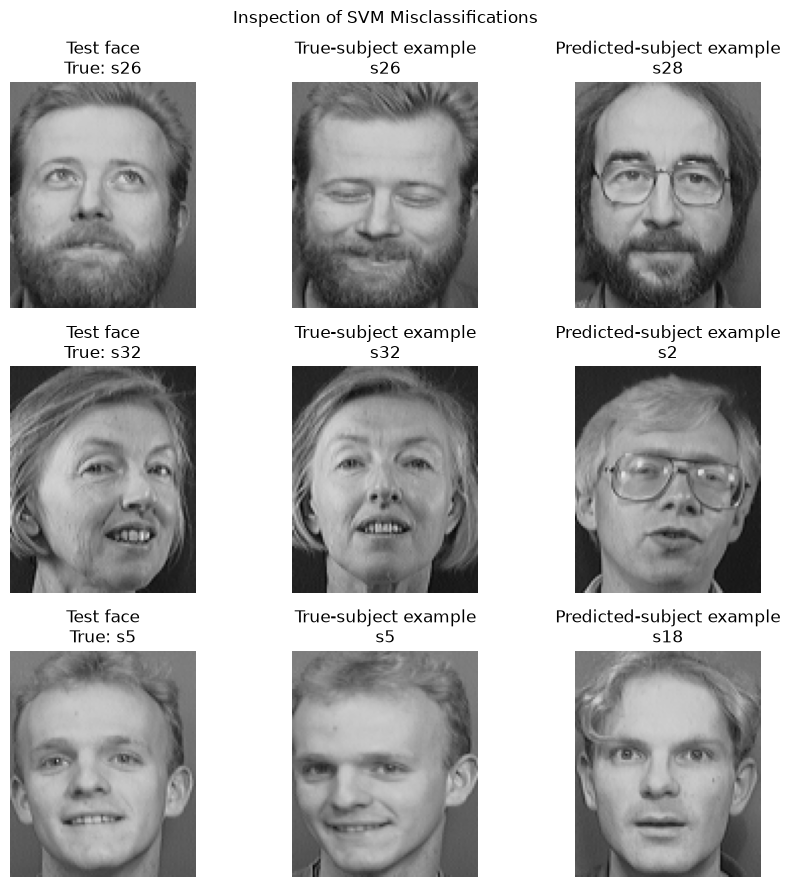

In [31]:
fig, axes = plt.subplots(
    len(svm_error_positions), 3,
    figsize=(9, 3 * len(svm_error_positions)),
    squeeze=False
)

for row, test_position in enumerate(svm_error_positions):
    true_subject = y_test[test_position]
    predicted_subject = pred_svm[test_position]

    # Select the closest training example within each subject
    # using the same PCA features supplied to the SVM.
    reference_indices = []

    for subject in [true_subject, predicted_subject]:
        candidates = np.where(y_train == subject)[0]

        distances = np.sum(
            (Z_train_svm[candidates] - Z_test_svm[test_position]) ** 2,
            axis=1
        )

        reference_indices.append(candidates[np.argmin(distances)])

    faces = [
        X_test[test_position],
        X_train[reference_indices[0]],
        X_train[reference_indices[1]]
    ]

    titles = [
        f"Test face\nTrue: {true_subject}",
        f"True-subject example\n{true_subject}",
        f"Predicted-subject example\n{predicted_subject}"
    ]

    for col, (face, title) in enumerate(zip(faces, titles)):
        axes[row, col].imshow(
            face.reshape(image_shape),
            cmap="gray", vmin=0, vmax=255
        )
        axes[row, col].set_title(title)
        axes[row, col].axis("off")

fig.suptitle("Inspection of SVM Misclassifications")
plt.tight_layout()
plt.show()

## We save PCA coordinates, the basis, labels, split indices, and evaluation tables so the reduced representation and results can be reused and documented.


In [32]:
OUTPUT_DIR = DATA_DIR.parent / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the 90%-variance PCA representation and reconstruction parameters.
np.savez_compressed(
    OUTPUT_DIR / "pca_representation.npz",
    Z_train=Z_train,
    Z_test=Z_test,
    mean_face=mean_face,
    W=W,
    y_train=y_train,
    y_test=y_test,
    train_indices=train_indices,
    test_indices=test_indices,
    image_shape=np.array(image_shape),
    filenames=metadata["filename"].to_numpy(dtype=str),
    explained_variance_ratio=explained_variance_ratio,
    k_90=np.array(k_90)
)

# Save analysis and evaluation tables.
metadata.to_csv(OUTPUT_DIR / "image_metadata.csv", index=False)
final_results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
knn_results.to_csv(OUTPUT_DIR / "knn_validation_results.csv", index=False)
svm_results.to_csv(OUTPUT_DIR / "svm_validation_results.csv", index=False)
diagnostics.to_csv(OUTPUT_DIR / "fitting_validation_diagnostics.csv", index=False)
svm_errors.to_csv(OUTPUT_DIR / "svm_errors.csv", index=False)
storage_table.to_csv(OUTPUT_DIR / "storage_comparison.csv", index=False)
pd.DataFrame(svm_report).T.to_csv(
    OUTPUT_DIR / "svm_classification_report.csv"
)

print("Saved outputs to:", OUTPUT_DIR)

for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(path.name)

Saved outputs to: C:\Users\rajab\202618066_Abhikarsh_Raj_DS605\202618066_LAB_7\outputs
fitting_validation_diagnostics.csv
image_metadata.csv
knn_validation_results.csv
model_comparison.csv
pca_representation.npz
storage_comparison.csv
svm_classification_report.csv
svm_errors.csv
svm_validation_results.csv


In [33]:
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Cumulative explained variance
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance * 100
)
ax.axhline(90, color="red", linestyle="--", label="90% target")
ax.axvline(
    k_90, color="green", linestyle="--",
    label=f"{k_90} components"
)
ax.set(
    title="Cumulative Explained Variance",
    xlabel="Number of principal components",
    ylabel="Explained variance (%)"
)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "explained_variance.png", dpi=200)
plt.close(fig)

# 2. First ten eigenfaces
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    face = principal_components[i].reshape(image_shape)
    limit = np.abs(face).max()

    ax.imshow(face, cmap="gray", vmin=-limit, vmax=limit)
    ax.set_title(
        f"PC {i + 1}\n"
        f"{explained_variance_ratio[i] * 100:.2f}% variance"
    )
    ax.axis("off")

fig.suptitle("First 10 Eigenfaces")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eigenfaces.png", dpi=200)
plt.close(fig)

# 3. Original and reconstructed test faces
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i in range(5):
    axes[0, i].imshow(
        X_test[i].reshape(image_shape),
        cmap="gray", vmin=0, vmax=255
    )
    axes[0, i].set_title(f"Original: {y_test[i]}")

    axes[1, i].imshow(
        np.clip(X_test_reconstructed[i], 0, 255).reshape(image_shape),
        cmap="gray", vmin=0, vmax=255
    )
    axes[1, i].set_title(f"{k_90} components")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

fig.suptitle("Test Face Reconstruction")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "reconstruction.png", dpi=200)
plt.close(fig)

# 4. Final model comparison
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    final_results["Method"],
    final_results["Test accuracy (%)"],
    color=["gray", "steelblue", "orange", "seagreen"]
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)
ax.set(
    title="Final Test Accuracy — 120 Images",
    ylabel="Accuracy (%)",
    ylim=(0, 105)
)
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "model_comparison.png", dpi=200)
plt.close(fig)

print("Figures saved to:", FIGURE_DIR)
for path in sorted(FIGURE_DIR.glob("*.png")):
    print(path.name)

Figures saved to: C:\Users\rajab\202618066_Abhikarsh_Raj_DS605\202618066_LAB_7\outputs\figures
eigenfaces.png
explained_variance.png
model_comparison.png
reconstruction.png
